# 02 · EDA – Exploratory Data Analysis
**Challenge 2 – Phân loại bài hát theo `Class` (11 lớp: 0 → 10)**

Nội dung:
1. Tổng quan dữ liệu: số dòng, số cột, kiểu dữ liệu
2. Chất lượng dữ liệu: missing values, duplicates, giá trị bất thường
3. Phân phối các đặc trưng
4. Tương quan giữa các biến
5. Phân tích biến mục tiêu (`Class`)
6. Tổng kết & việc cần làm ở bước Preprocessing

In [22]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

try:
    from IPython.display import display
except ImportError:          # chạy ngoài Jupyter
    display = print

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RANDOM_STATE = 42

# Tự tìm thư mục DATA_CHALLENGE2 (đi ngược lên từ thư mục notebook)
DATA_DIR = next(p / "DATA_CHALLENGE2" for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "DATA_CHALLENGE2").exists())
train = pd.read_csv(next(DATA_DIR.glob("train*.csv")))
test = pd.read_csv(next(DATA_DIR.glob("test*.csv")))
sample = pd.read_csv(next(DATA_DIR.glob("sample_submission*.csv")))
print("Data dir:", DATA_DIR)

TARGET, ID, DUR = "Class", "Id", "duration_in min/ms"
CONT = ["Popularity", "danceability", "energy", "loudness", "speechiness",
        "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
DISC = ["key", "mode", "time_signature"]
FEATS = CONT + DISC + [DUR]

# ===== NHẬT KÝ THÍ NGHIỆM =====
import sys
sys.path.insert(0, str(DATA_DIR.parent / "notebooks"))
from logger_utils import ExperimentLogger

RUNNER = "Tô Doanh Quang Khu"      # <-- ĐỔI thành họ tên của bạn (hoặc tên nhóm) trước khi chạy
log = ExperimentLogger(runner=RUNNER, stage="02_EDA", notebook="02_EDA.ipynb",
                       log_dir=DATA_DIR.parent / "logs",
                       goal="EDA: khám phá dữ liệu train/test, missing, duplicates, phân phối, tương quan, target")

Data dir: d:\May Hoc\CK_ML\MAY_HOC_NHOM\Challenge\Challenge 2\DATA_CHALLENGE2


## 1. Tổng quan dữ liệu

In [23]:
print(f"train             : {train.shape[0]:>6,} dòng × {train.shape[1]} cột")
print(f"test              : {test.shape[0]:>6,} dòng × {test.shape[1]} cột")
print(f"sample_submission : {sample.shape[0]:>6,} dòng × {sample.shape[1]} cột")
print("Cột có ở train nhưng không có ở test:", set(train.columns) - set(test.columns))

info = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "n_missing": train.isna().sum(),
    "ví dụ": train.iloc[0],
})
display(info)

train             : 14,396 dòng × 18 cột
test              :  3,600 dòng × 17 cột
sample_submission :  3,600 dòng × 2 cột
Cột có ở train nhưng không có ở test: {'Class'}


,dtype,n_unique,n_missing,ví dụ
Id,int64,14396,0,1
Artist Name,object,7913,0,Marina Maximilian
Track Name,object,12455,0,Not Afraid
Popularity,float64,100,333,37.0000
danceability,float64,887,0,0.3340
energy,float64,1156,0,0.5360
key,float64,11,1609,9.0000
loudness,float64,8051,0,-6.6490
mode,int64,2,0,0
speechiness,float64,1177,0,0.0381


In [24]:
display(train.head())
display(train.describe().T)
display(train.describe(include=["object", "string"]).T)

,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0000,0.3340,0.5360,9.0000,-6.6490,0,0.0381,0.3780,NaN,0.1060,0.2350,152.4290,"204,947.0000",4,9
1,2,The Black Keys,Howlin' for You,67.0000,0.7250,0.7470,11.0000,-5.5450,1,0.0876,0.0272,0.0468,0.1040,0.3800,132.9210,"191,956.0000",4,6
2,3,Royal & the Serpent,phuck u,NaN,0.5840,0.8040,7.0000,-6.0940,1,0.0619,0.0010,0.6350,0.2840,0.6350,159.9530,"161,037.0000",4,10
3,4,Detroit Blues Band,Missing You,12.0000,0.5150,0.3080,NaN,-14.7110,1,0.0312,0.9070,0.0213,0.3000,0.5010,172.4720,"298,093.0000",3,2
4,5,Coast Contra,My Lady,48.0000,0.5650,0.7770,6.0000,-5.0960,0,0.2490,0.1830,NaN,0.2110,0.6190,88.3110,"254,145.0000",4,5


,count,mean,std,min,25%,50%,75%,max
Id,"14,396.0000","7,198.5000","4,155.9116",1.0000,"3,599.7500","7,198.5000","10,797.2500","14,396.0000"
Popularity,"14,063.0000",44.5252,17.4189,1.0000,33.0000,44.0000,56.0000,100.0000
danceability,"14,396.0000",0.5431,0.1655,0.0596,0.4320,0.5450,0.6580,0.9890
energy,"14,396.0000",0.6624,0.2360,0.0012,0.5080,0.6990,0.8610,1.0000
key,"12,787.0000",5.9538,3.2000,1.0000,3.0000,6.0000,9.0000,11.0000
loudness,"14,396.0000",-7.9009,4.0574,-39.9520,-9.5380,-7.0135,-5.1620,1.3420
mode,"14,396.0000",0.6402,0.4799,0.0000,0.0000,1.0000,1.0000,1.0000
speechiness,"14,396.0000",0.0802,0.0852,0.0225,0.0348,0.0471,0.0831,0.9550
acousticness,"14,396.0000",0.2467,0.3109,0.0000,0.0043,0.0814,0.4323,0.9960
instrumentalness,"10,855.0000",0.1781,0.3043,0.0000,0.0001,0.0039,0.2010,0.9960


,count,unique,top,freq
Artist Name,14396,7913,Backstreet Boys,58
Track Name,14396,12455,Fire,8


In [25]:
# Kiểm tra cột Id và khớp với file nộp bài
print("Id train liên tục 1..N :", train[ID].is_monotonic_increasing and train[ID].iloc[-1] == len(train))
print("Id test bắt đầu từ     :", test[ID].min(), "→", test[ID].max())
print("Id test == Id sample_submission:", set(test[ID]) == set(sample[ID]))
print("Id trùng giữa train và test    :", len(set(train[ID]) & set(test[ID])))

Id train liên tục 1..N : True
Id test bắt đầu từ     : 14397 → 17996
Id test == Id sample_submission: True
Id trùng giữa train và test    : 0


**Nhận xét ban đầu**
- `Id` chỉ là mã định danh → bỏ khỏi tập đặc trưng. `Artist Name`, `Track Name` là chuỗi (text/high-cardinality).
- 3 biến rời rạc: `key`, `mode`, `time_signature`; các biến còn lại là liên tục (đa số thang 0–1, trừ `Popularity`, `loudness`, `tempo`, `duration`).
- `Class` là số nguyên 0–10 nhưng bản chất là **nhãn phân loại** (không có thứ tự) → bài toán multi-class classification.

## 2. Chất lượng dữ liệu
### 2.1 Missing values

train              test        
                 n_missing       % n_missing       %
Popularity             333  2.3131        95  2.6389
key                   1609 11.1767       405 11.2500
instrumentalness      3541 24.5971       836 23.2222

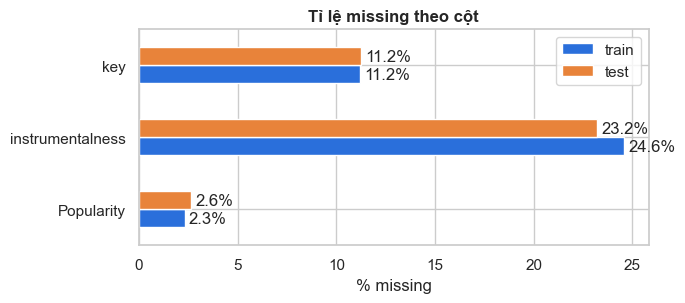

In [26]:
def missing_table(df):
    m = df.isna().sum()
    return pd.DataFrame({"n_missing": m, "%": m / len(df) * 100})[m > 0]

miss = pd.concat({"train": missing_table(train), "test": missing_table(test)}, axis=1)
display(miss)

fig, ax = plt.subplots(figsize=(7, 3.2))
pct = pd.DataFrame({"train": train[FEATS].isna().mean() * 100,
                    "test": test[FEATS].isna().mean() * 100})
pct = pct[(pct > 0).any(axis=1)]
pct.plot.barh(ax=ax, color=["#2a6fdb", "#e8833a"])
ax.set_xlabel("% missing"); ax.set_title("Tỉ lệ missing theo cột")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3)
plt.tight_layout(); plt.show()

,Popularity,key,instrumentalness
Class,,,
0,12.0000,10.6000,24.2000
1,1.9000,11.0000,12.8000
2,1.1000,15.3000,10.8000
3,3.7000,8.4000,24.2000
4,6.1000,11.3000,53.5000
5,1.4000,7.3000,61.4000
6,1.6000,11.3000,10.8000
7,4.1000,15.8000,0.2000
8,1.6000,8.6000,8.5000


Popularity         chi2 =    263.5   p-value = 8.02e-51
key                chi2 =     59.5   p-value = 4.42e-09
instrumentalness   chi2 =   2428.6   p-value = 0.00e+00


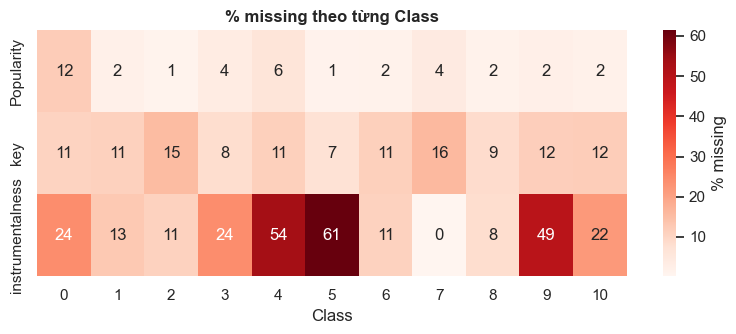

In [27]:
# Missing có phụ thuộc vào Class không? (nếu có → bản thân việc "bị thiếu" là một tín hiệu)
na_cols = ["Popularity", "key", "instrumentalness"]
na_by_class = train.groupby(TARGET)[na_cols].agg(lambda s: s.isna().mean() * 100)
display(na_by_class.round(1))

for c in na_cols:
    ct = pd.crosstab(train[c].isna(), train[TARGET])
    chi2, p, *_ = stats.chi2_contingency(ct)
    print(f"{c:<18} chi2 = {chi2:8.1f}   p-value = {p:.2e}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(na_by_class.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("% missing theo từng Class"); plt.tight_layout(); plt.show()

### 2.2 Duplicates

In [28]:
feat_cols = [c for c in train.columns if c not in (ID, TARGET)]

print("Trùng toàn bộ dòng (kể cả Id)            :", train.duplicated().sum())
print("Trùng toàn bộ đặc trưng (bỏ Id, Class)   :", train.duplicated(subset=feat_cols).sum())
print("Trùng (Artist Name, Track Name)          :", train.duplicated(subset=["Artist Name", "Track Name"]).sum())

# Các bản ghi trùng đặc trưng có cùng nhãn không?
g = train.groupby(feat_cols, dropna=False)[TARGET].agg(["size", "nunique"])
dup_groups = g[g["size"] > 1]
print(f"\nSố nhóm bản ghi trùng đặc trưng : {len(dup_groups):,}")
print(f"  - nhóm có nhãn mâu thuẫn        : {(dup_groups['nunique'] > 1).sum():,}")
print(f"  - nhóm cùng nhãn                : {(dup_groups['nunique'] == 1).sum():,}")

# Bài hát của test đã xuất hiện trong train
key_tr = train[["Artist Name", "Track Name"]].drop_duplicates()
overlap = test.merge(key_tr, on=["Artist Name", "Track Name"], how="inner")
print(f"\nBài hát (Artist+Track) của test đã có trong train: {len(overlap):,} / {len(test):,} "
      f"({len(overlap) / len(test) * 100:.1f}%)")
display(train[train.duplicated(subset=feat_cols, keep=False)].sort_values(["Artist Name", "Track Name"]).head(8))

Trùng toàn bộ dòng (kể cả Id)            : 0
Trùng toàn bộ đặc trưng (bỏ Id, Class)   : 1081
Trùng (Artist Name, Track Name)          : 1220

Số nhóm bản ghi trùng đặc trưng : 979
  - nhóm có nhãn mâu thuẫn        : 979
  - nhóm cùng nhãn                : 0

Bài hát (Artist+Track) của test đã có trong train: 607 / 3,600 (16.9%)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
382,383,'68,Bad Bite,36.0000,0.5580,0.9770,1.0000,-5.0820,1,0.2110,0.0006,0.0013,0.3160,0.4730,167.9840,"190,031.0000",4,1
6235,6236,'68,Bad Bite,36.0000,0.5580,0.9770,1.0000,-5.0820,1,0.2110,0.0006,0.0013,0.3160,0.4730,167.9840,"190,031.0000",4,6
8214,8215,'68,Bad Bite,36.0000,0.5580,0.9770,1.0000,-5.0820,1,0.2110,0.0006,0.0013,0.3160,0.4730,167.9840,"190,031.0000",4,10
6408,6409,100 gecs,money machine,70.0000,0.6800,0.6590,6.0000,-7.1860,1,0.1510,0.2290,NaN,0.4740,0.7500,98.8770,"114,460.0000",4,9
10871,10872,100 gecs,money machine,70.0000,0.6800,0.6590,6.0000,-7.1860,1,0.1510,0.2290,NaN,0.4740,0.7500,98.8770,"114,460.0000",4,6
6343,6344,1000mods,Mirrors,35.0000,0.3330,0.8200,5.0000,-7.3610,1,0.0531,0.0003,0.2640,0.0891,0.1620,115.1200,"436,333.0000",4,8
8186,8187,1000mods,Mirrors,35.0000,0.3330,0.8200,5.0000,-7.3610,1,0.0531,0.0003,0.2640,0.0891,0.1620,115.1200,"436,333.0000",4,10
7922,7923,13th Floor Elevators,Slip Inside This House - Stereo LP Version,43.0000,0.5550,0.6940,9.0000,-8.4530,0,0.0426,0.1010,NaN,0.1230,0.6020,127.4230,"482,278.0000",4,10


### 2.3 Giá trị bất thường

Khoảng giá trị duration: 0.50165 → 1477187.0
Số dòng < 100          : 2075 (nhiều khả năng là PHÚT)
Số dòng 100 ≤ x < 1000 : 0
Số dòng ≥ 1000         : 12321 (nhiều khả năng là MILI-GIÂY)
Test: số dòng < 100    : 505 / 3600


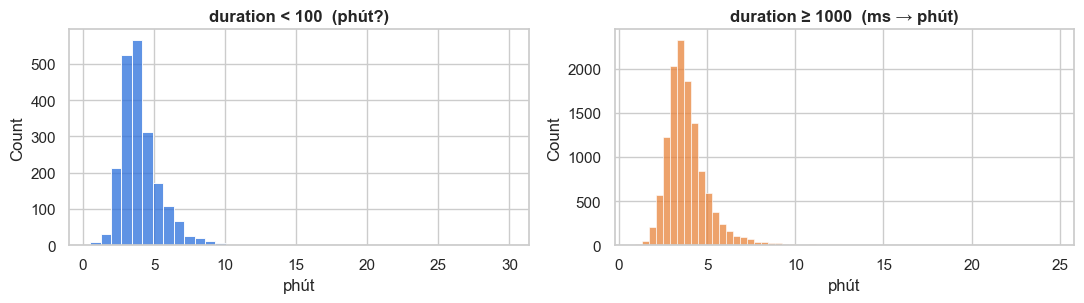

,count,mean,std,min,25%,50%,75%,max
duration_min,"14,396.0000",3.9204,1.4062,0.5017,3.1222,3.6633,4.3742,29.8860


In [29]:
# (a) Cột duration lẫn đơn vị: phút và mili-giây
d = train[DUR]
print("Khoảng giá trị duration:", d.min(), "→", d.max())
print("Số dòng < 100          :", (d < 100).sum(), "(nhiều khả năng là PHÚT)")
print("Số dòng 100 ≤ x < 1000 :", ((d >= 100) & (d < 1000)).sum())
print("Số dòng ≥ 1000         :", (d >= 1000).sum(), "(nhiều khả năng là MILI-GIÂY)")
print("Test: số dòng < 100    :", (test[DUR] < 100).sum(), "/", len(test))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.histplot(d[d < 100], bins=40, ax=axes[0], color="#2a6fdb"); axes[0].set_title("duration < 100  (phút?)")
sns.histplot(d[d >= 1000] / 60000, bins=60, ax=axes[1], color="#e8833a"); axes[1].set_title("duration ≥ 1000  (ms → phút)")
for a in axes: a.set_xlabel("phút")
plt.tight_layout(); plt.show()

# Chuẩn hoá về phút để dùng cho toàn bộ phần EDA phía sau (chưa sửa dữ liệu gốc)
def add_dur_min(df):
    df = df.copy()
    df["duration_min"] = np.where(df[DUR] < 1000, df[DUR], df[DUR] / 60000)
    df["dur_was_minutes"] = (df[DUR] < 1000).astype(int)
    return df

train = add_dur_min(train); test = add_dur_min(test)
display(train["duration_min"].describe().to_frame().T)

In [30]:
# (b) Các cột khác: tần suất của key / time_signature / mode và giá trị cực trị
print("key (kể cả NaN):", train["key"].value_counts(dropna=False).sort_index().to_dict())
print("→ key chỉ nhận 1..11, không có giá trị 0; NaN có thể chính là nốt C (0) bị mất → cần xử lý riêng.\n")
print("time_signature:", train["time_signature"].value_counts().sort_index().to_dict())
print("mode          :", train["mode"].value_counts().sort_index().to_dict())
print()
print("loudness < -30 dB :", (train["loudness"] < -30).sum())
print("tempo < 50 BPM    :", (train["tempo"] < 50).sum())
print("speechiness > 0.66:", (train["speechiness"] > 0.66).sum(), "(thường là lời nói/podcast)")

key (kể cả NaN): {1.0: 1351, 2.0: 1582, 3.0: 411, 4.0: 1252, 5.0: 1115, 6.0: 963, 7.0: 1650, 8.0: 872, 9.0: 1590, 10.0: 825, 11.0: 1176, nan: 1609}
→ key chỉ nhận 1..11, không có giá trị 0; NaN có thể chính là nốt C (0) bị mất → cần xử lý riêng.

time_signature: {1: 87, 3: 994, 4: 13149, 5: 166}
mode          : {0: 5179, 1: 9217}

loudness < -30 dB : 20
tempo < 50 BPM    : 7
speechiness > 0.66: 13 (thường là lời nói/podcast)


## 3. Phân phối các đặc trưng
### 3.1 Biến liên tục

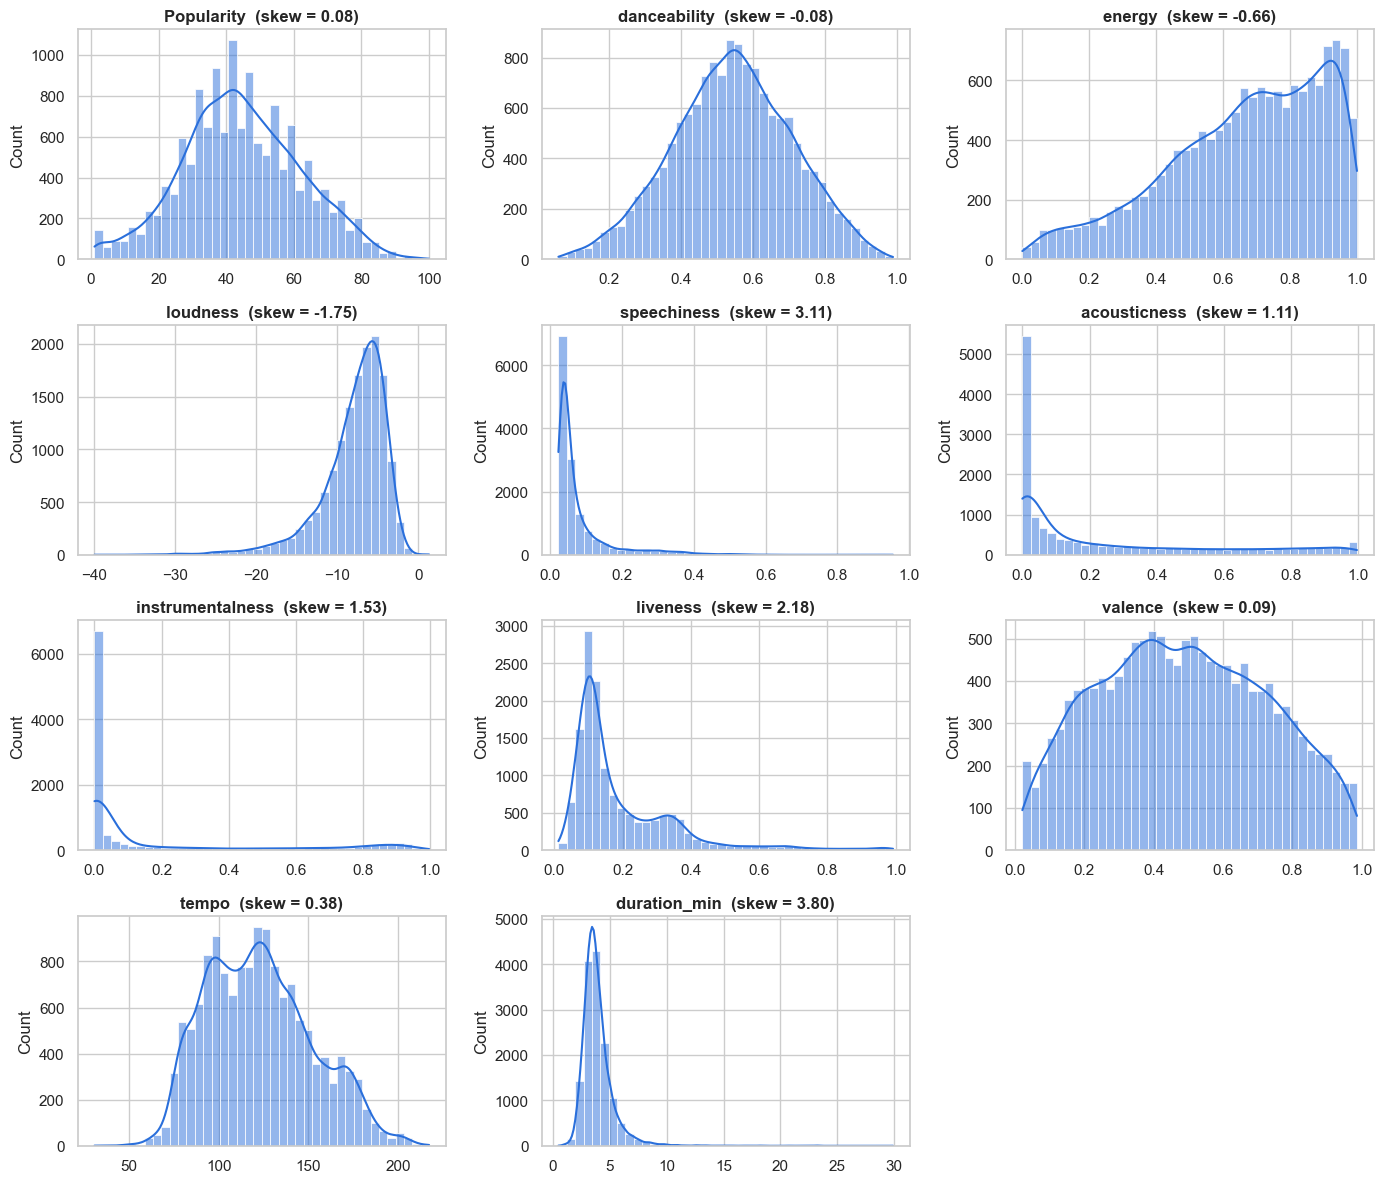

,skew,kurtosis
loudness,-1.7481,4.9797
energy,-0.6567,-0.3286
danceability,-0.0757,-0.2799
Popularity,0.0758,-0.1979
valence,0.0887,-0.9124
tempo,0.3765,-0.4459
acousticness,1.1089,-0.1790
instrumentalness,1.5252,0.7022
liveness,2.1783,5.6448
speechiness,3.1134,12.8703


In [31]:
CONT2 = CONT + ["duration_min"]
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, c in zip(axes.ravel(), CONT2):
    sns.histplot(train[c].dropna(), bins=40, kde=True, ax=ax, color="#2a6fdb")
    ax.set_title(f"{c}  (skew = {train[c].skew():.2f})"); ax.set_xlabel("")
for ax in axes.ravel()[len(CONT2):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

shape = pd.DataFrame({"skew": train[CONT2].skew(), "kurtosis": train[CONT2].kurt()}).sort_values("skew")
display(shape)

,n_outliers,%
instrumentalness,1940,13.4760
speechiness,1633,11.3434
liveness,767,5.3279
duration_min,736,5.1125
loudness,648,4.5013
Popularity,32,0.2223
tempo,32,0.2223
danceability,29,0.2014
energy,0,0.0000
acousticness,0,0.0000


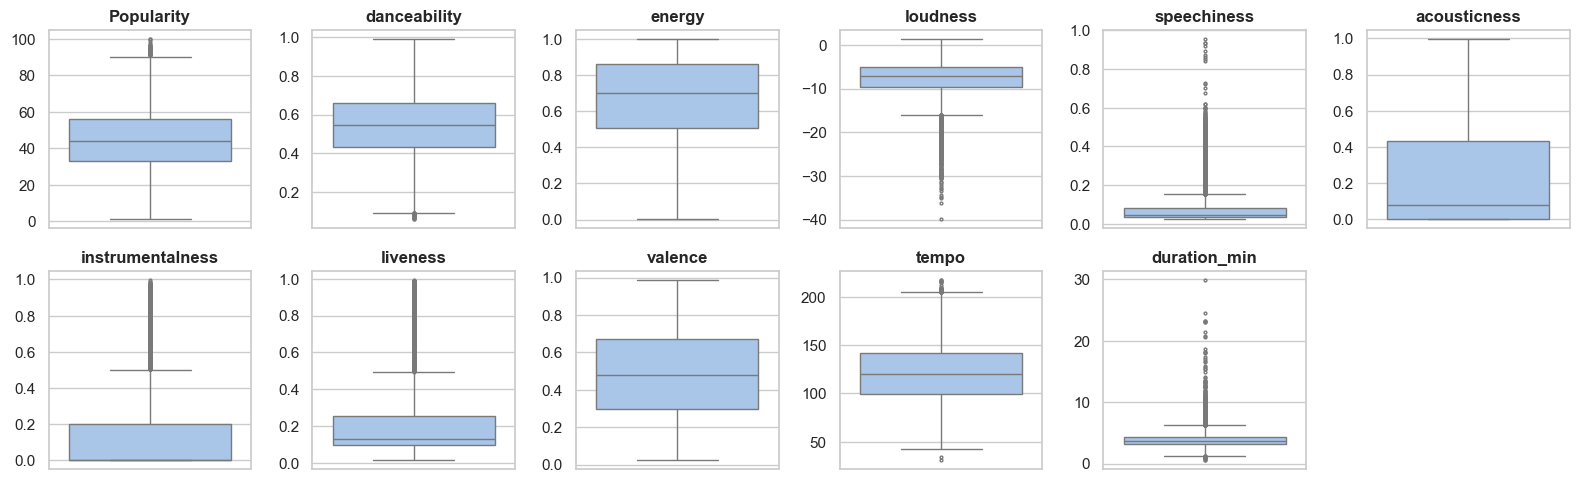

In [32]:
# Outlier theo quy tắc IQR (1.5 × IQR) + boxplot
def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

out = pd.DataFrame({"n_outliers": {c: iqr_outliers(train[c]) for c in CONT2}})
out["%"] = out["n_outliers"] / len(train) * 100
display(out.sort_values("%", ascending=False))

fig, axes = plt.subplots(2, 6, figsize=(16, 5))
for ax, c in zip(axes.ravel(), CONT2):
    sns.boxplot(y=train[c], ax=ax, color="#9ec5f4", fliersize=2); ax.set_title(c); ax.set_ylabel("")
for ax in axes.ravel()[len(CONT2):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 3.2 Biến rời rạc

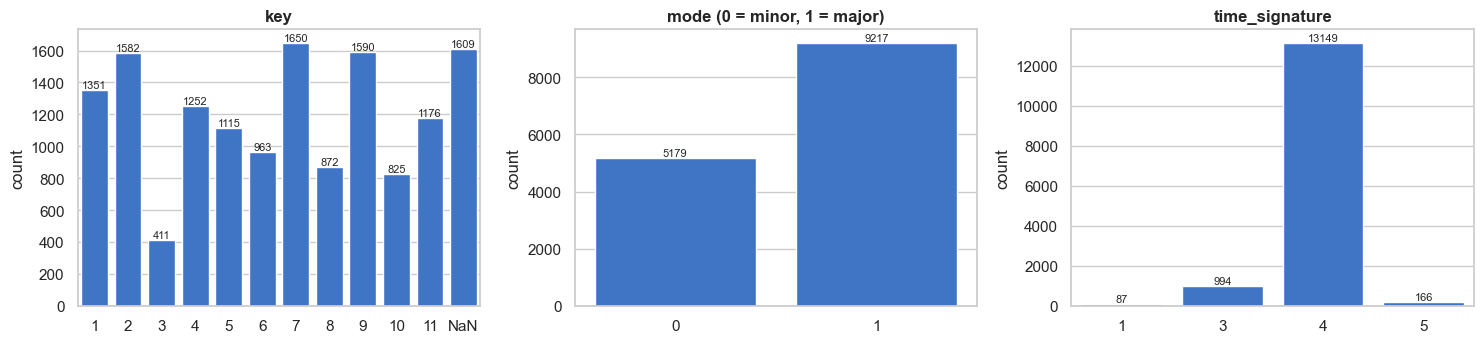

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
order_key = [*range(1, 12), "NaN"]
k = train["key"].map(lambda v: "NaN" if pd.isna(v) else int(v)).astype(str)
sns.countplot(x=k, order=[str(o) for o in order_key], ax=axes[0], color="#2a6fdb"); axes[0].set_title("key")
sns.countplot(x=train["mode"], ax=axes[1], color="#2a6fdb"); axes[1].set_title("mode (0 = minor, 1 = major)")
sns.countplot(x=train["time_signature"], ax=axes[2], color="#2a6fdb"); axes[2].set_title("time_signature")
for ax in axes:
    ax.set_xlabel("")
    for c in ax.containers: ax.bar_label(c, fontsize=8)
plt.tight_layout(); plt.show()

### 3.3 Artist / Track

Số nghệ sĩ khác nhau : 7913 / 14396 dòng
Số bài hát khác nhau : 12455
Nghệ sĩ chỉ xuất hiện 1 lần: 66.8 %
Nghệ sĩ test có trong train : 63.800000000000004 % số dòng


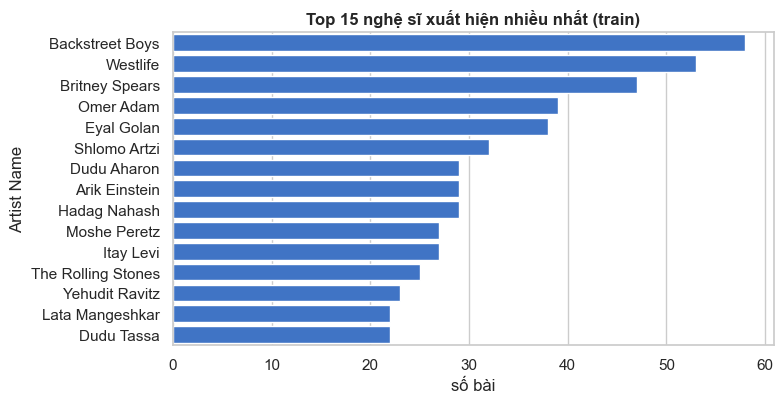

In [34]:
print("Số nghệ sĩ khác nhau :", train["Artist Name"].nunique(), "/", len(train), "dòng")
print("Số bài hát khác nhau :", train["Track Name"].nunique())
print("Nghệ sĩ chỉ xuất hiện 1 lần:", (train["Artist Name"].value_counts() == 1).mean().round(3) * 100, "%")
print("Nghệ sĩ test có trong train :",
      test["Artist Name"].isin(set(train["Artist Name"])).mean().round(3) * 100, "% số dòng")

top = train["Artist Name"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=top.values, y=top.index, color="#2a6fdb", ax=ax)
ax.set_title("Top 15 nghệ sĩ xuất hiện nhiều nhất (train)"); ax.set_xlabel("số bài")
plt.tight_layout(); plt.show()

### 3.4 So sánh phân phối Train và Test
Nếu phân phối hai tập lệch nhau, mô hình huấn luyện trên train sẽ kém ổn định trên test.

,KS stat,p-value
feature,,
loudness,0.0222,0.1161
speechiness,0.0201,0.1935
tempo,0.0176,0.3304
mode,0.0175,0.3392
duration_min,0.0172,0.3576
liveness,0.0163,0.4257
danceability,0.0156,0.4768
acousticness,0.0146,0.5639
instrumentalness,0.0145,0.7389


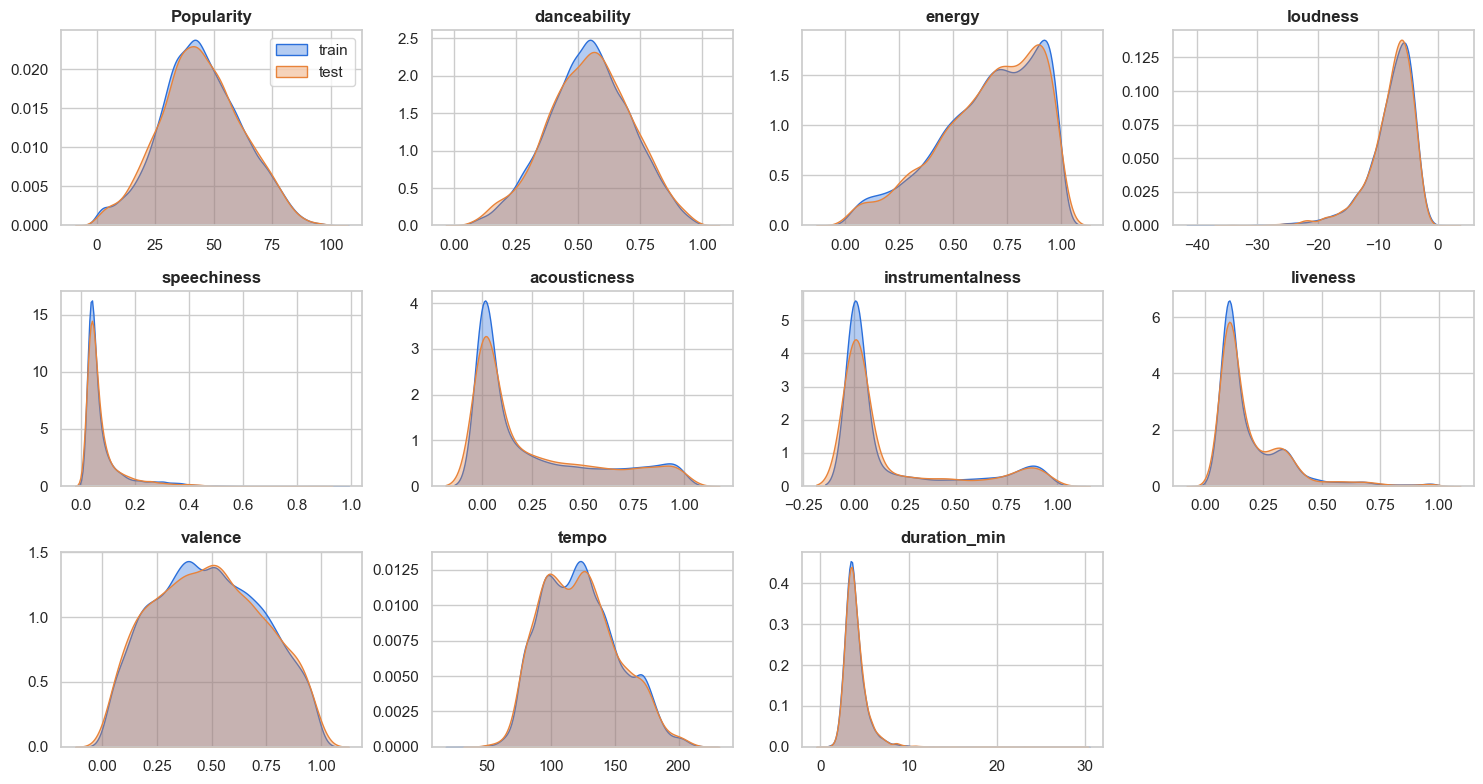

In [35]:
rows = []
for c in CONT2 + DISC:
    ks = stats.ks_2samp(train[c].dropna(), test[c].dropna())
    rows.append((c, ks.statistic, ks.pvalue))
ks_df = pd.DataFrame(rows, columns=["feature", "KS stat", "p-value"]).set_index("feature")
display(ks_df.sort_values("KS stat", ascending=False))

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, c in zip(axes.ravel(), CONT2):
    sns.kdeplot(train[c].dropna(), ax=ax, label="train", fill=True, alpha=.35, color="#2a6fdb")
    sns.kdeplot(test[c].dropna(), ax=ax, label="test", fill=True, alpha=.35, color="#e8833a")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(CONT2):]:
    ax.axis("off")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

## 4. Tương quan giữa các biến

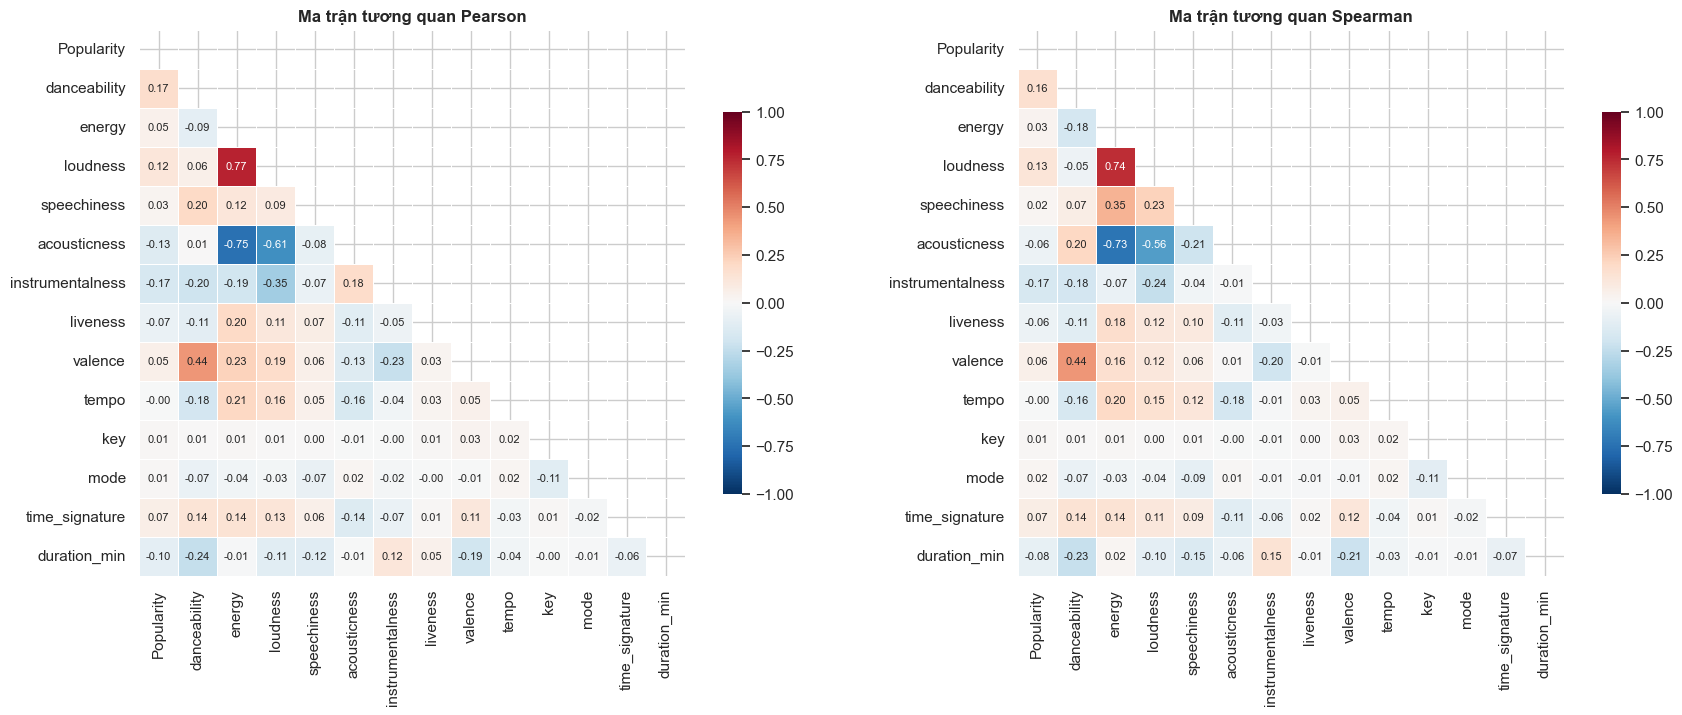

In [36]:
NUM = CONT + DISC + ["duration_min"]
corr_p = train[NUM].corr(method="pearson")
corr_s = train[NUM].corr(method="spearman")
mask = np.triu(np.ones_like(corr_p, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, cm, name in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, linewidths=.4, cbar_kws={"shrink": .7}, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Ma trận tương quan {name}")
plt.tight_layout(); plt.show()

pearson  spearman  |pearson|
loudness         energy             0.7696    0.7351     0.7696
acousticness     energy            -0.7464   -0.7283     0.7464
                 loudness          -0.6150   -0.5604     0.6150
valence          danceability       0.4448    0.4379     0.4448
instrumentalness loudness          -0.3507   -0.2396     0.3507
duration_min     danceability      -0.2369   -0.2339     0.2369
valence          instrumentalness  -0.2287   -0.1983     0.2287
                 energy             0.2275    0.1636     0.2275
tempo            energy             0.2054    0.2022     0.2054
instrumentalness danceability      -0.2033   -0.1822     0.2033

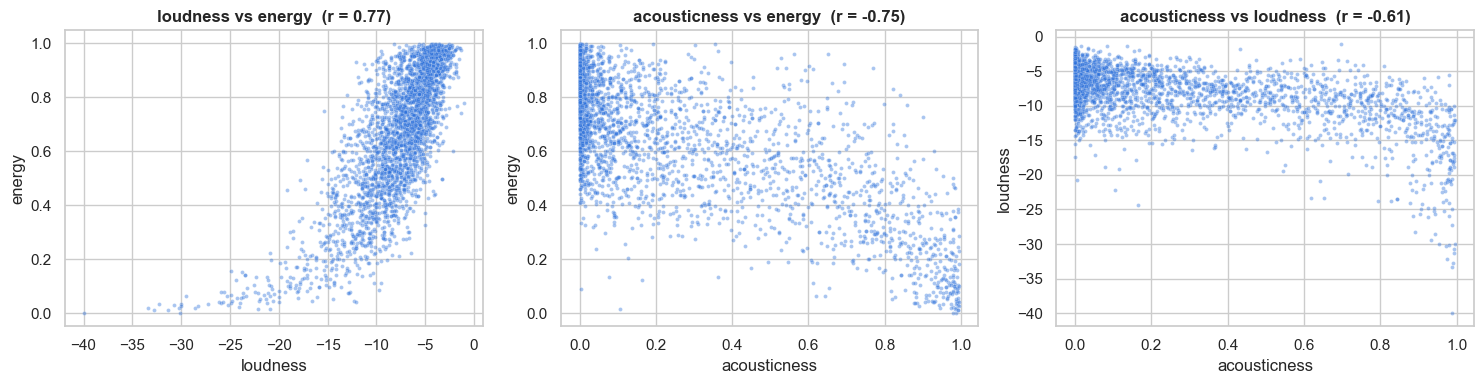

In [37]:
# Các cặp biến tương quan mạnh nhất (|r| theo Pearson)
pairs = (corr_p.where(~mask).stack().rename("pearson").to_frame()
         .join(corr_s.where(~mask).stack().rename("spearman")))
pairs["|pearson|"] = pairs["pearson"].abs()
top_pairs = pairs.sort_values("|pearson|", ascending=False).head(10)
display(top_pairs)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
smp = train.sample(3000, random_state=RANDOM_STATE)
for ax, (a, b) in zip(axes, top_pairs.index[:3]):
    sns.scatterplot(data=smp, x=a, y=b, s=8, alpha=.4, ax=ax, color="#2a6fdb")
    ax.set_title(f"{a} vs {b}  (r = {corr_p.loc[a, b]:.2f})")
plt.tight_layout(); plt.show()

**Lưu ý:** các cặp có |r| lớn (thường là `energy` – `loudness` – `acousticness`) là đa cộng tuyến. Điều này ít ảnh hưởng đến mô hình cây (Random Forest/XGBoost…) nhưng cần cân nhắc với mô hình tuyến tính/KNN/SVM (chuẩn hoá, bỏ bớt hoặc dùng PCA).

## 5. Phân tích biến mục tiêu (`Class`)
### 5.1 Phân phối nhãn

,count,%
Class,,
0,500,3.4732
1,1098,7.6271
2,1018,7.0714
3,322,2.2367
4,310,2.1534
5,1157,8.0370
6,2069,14.3720
7,461,3.2023
8,1483,10.3015


Số lớp: 11 | lớp lớn nhất = 10 (3,959) | lớp nhỏ nhất = 4 (310) | tỉ lệ mất cân bằng = 12.8 : 1
Baseline nếu luôn đoán lớp phổ biến nhất: accuracy = 0.275


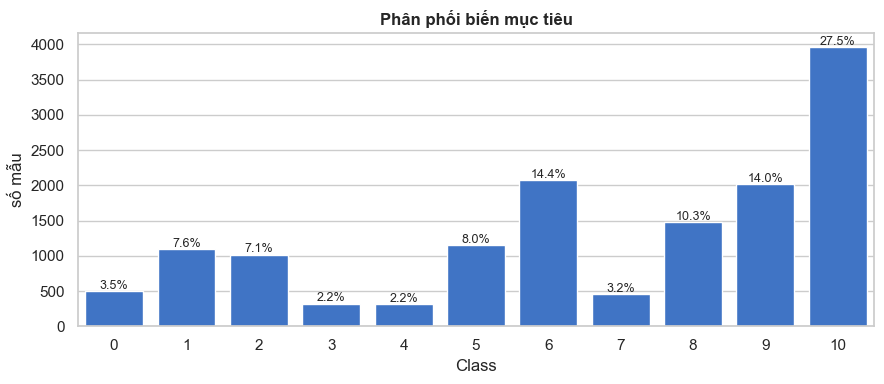

In [38]:
vc = train[TARGET].value_counts().sort_index()
cls_df = pd.DataFrame({"count": vc, "%": vc / vc.sum() * 100})
display(cls_df)
print(f"Số lớp: {vc.size} | lớp lớn nhất = {vc.idxmax()} ({vc.max():,}) | lớp nhỏ nhất = {vc.idxmin()} ({vc.min():,})"
      f" | tỉ lệ mất cân bằng = {vc.max() / vc.min():.1f} : 1")
print(f"Baseline nếu luôn đoán lớp phổ biến nhất: accuracy = {vc.max() / vc.sum():.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=vc.index, y=vc.values, color="#2a6fdb", ax=ax)
for i, v in enumerate(vc.values):
    ax.text(i, v + 30, f"{v / vc.sum() * 100:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("Class"); ax.set_ylabel("số mẫu"); ax.set_title("Phân phối biến mục tiêu")
plt.tight_layout(); plt.show()

### 5.2 Đặc trưng nào phân biệt được các lớp?
`Class` là biến định danh nên **không** dùng hệ số Pearson với `Class`. Thay vào đó dùng:
ANOVA F / **η²** (phần phương sai của đặc trưng được giải thích bởi Class) và **Mutual Information**.

,F,p-value,eta²,mutual_info
feature,,,,
acousticness,759.4938,0.0000,0.3455,0.2824
speechiness,690.5510,0.0000,0.3243,0.1515
energy,658.9287,0.0000,0.3142,0.2185
loudness,615.6129,0.0000,0.2997,0.1312
danceability,457.3380,0.0000,0.2412,0.1528
instrumentalness,301.1710,0.0000,0.2174,0.1642
valence,226.2405,0.0000,0.1359,0.0905
Popularity,163.7082,0.0000,0.1043,0.0917
duration_min,93.8714,0.0000,0.0613,0.0569


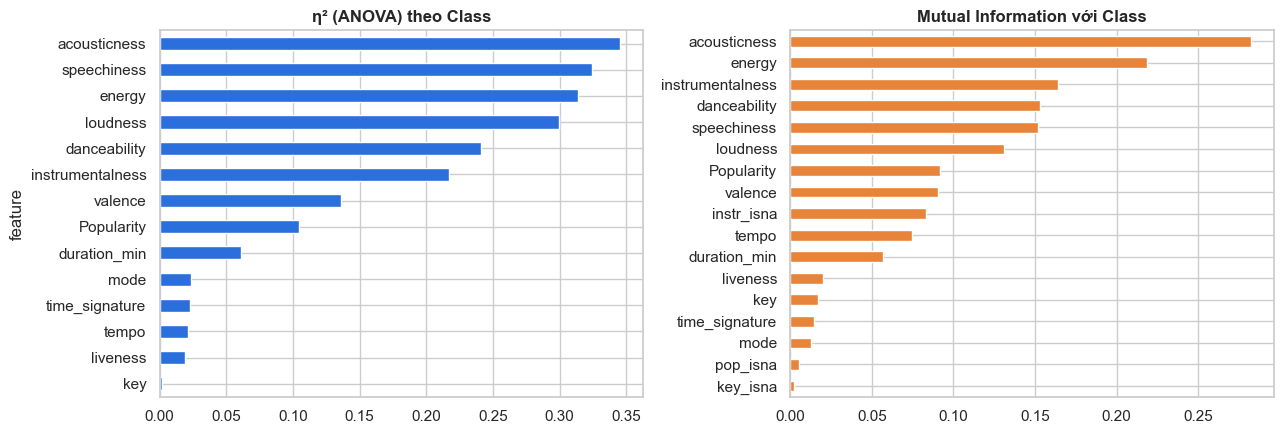

In [39]:
def eta_squared(df, col, by):
    x = df[[col, by]].dropna()
    grand = x[col].mean()
    ssb = x.groupby(by)[col].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    sst = ((x[col] - grand) ** 2).sum()
    return ssb / sst

feat_num = CONT + DISC + ["duration_min"]
rows = []
for c in feat_num:
    groups = [g[c].dropna().values for _, g in train.groupby(TARGET)]
    F, p = stats.f_oneway(*groups)
    rows.append((c, F, p, eta_squared(train, c, TARGET)))
anova = pd.DataFrame(rows, columns=["feature", "F", "p-value", "eta²"]).set_index("feature")

# Mutual information (điền median cho NaN + thêm cờ missing)
X = train[feat_num].copy()
for c, n in [("Popularity", "pop_isna"), ("key", "key_isna"), ("instrumentalness", "instr_isna")]:
    X[n] = train[c].isna().astype(int)
X = X.fillna(X.median())
disc_mask = [c in DISC or c.endswith("_isna") for c in X.columns]
mi = pd.Series(mutual_info_classif(X, train[TARGET], discrete_features=disc_mask, random_state=RANDOM_STATE),
               index=X.columns, name="mutual_info")
rank = anova.join(mi).sort_values("eta²", ascending=False)
display(rank)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rank["eta²"].sort_values().plot.barh(ax=axes[0], color="#2a6fdb"); axes[0].set_title("η² (ANOVA) theo Class")
mi.sort_values().plot.barh(ax=axes[1], color="#e8833a"); axes[1].set_title("Mutual Information với Class")
plt.tight_layout(); plt.show()

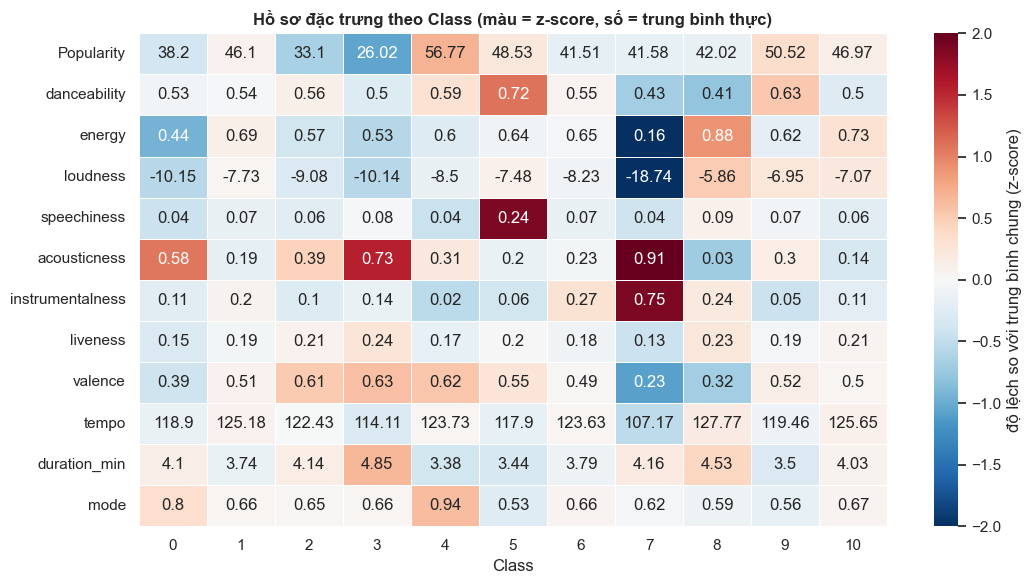

In [40]:
# Giá trị trung bình (chuẩn hoá z-score) của từng đặc trưng theo Class
prof_cols = [c for c in CONT + ["duration_min", "mode"] ]
means = train.groupby(TARGET)[prof_cols].mean()
z = (means - train[prof_cols].mean()) / train[prof_cols].std()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(z.T, annot=means.T.round(2), fmt="", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            linewidths=.4, cbar_kws={"label": "độ lệch so với trung bình chung (z-score)"}, ax=ax)
ax.set_title("Hồ sơ đặc trưng theo Class (màu = z-score, số = trung bình thực)")
plt.tight_layout(); plt.show()

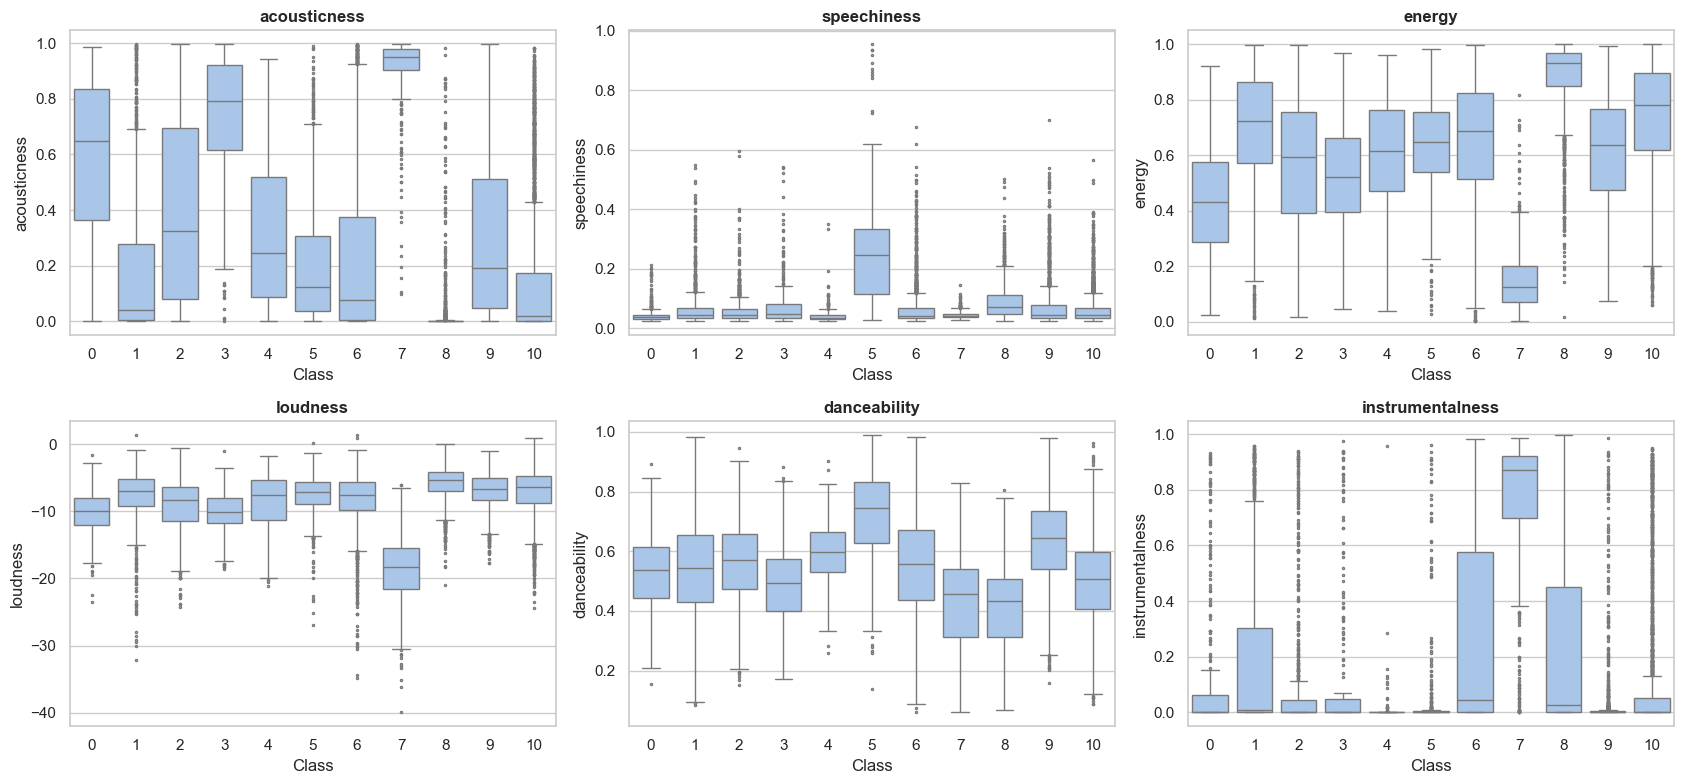

In [41]:
# Boxplot các đặc trưng phân biệt tốt nhất theo Class
top_feats = rank.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), top_feats):
    sns.boxplot(data=train, x=TARGET, y=c, ax=ax, color="#9ec5f4", fliersize=1.5)
    ax.set_title(c); ax.set_xlabel("Class")
plt.tight_layout(); plt.show()

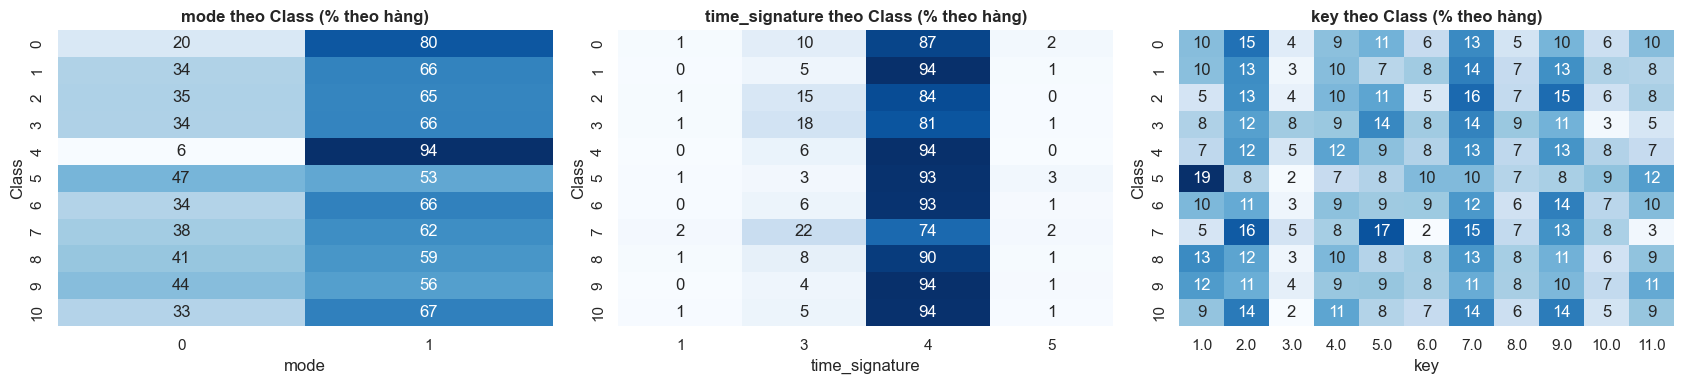

In [42]:
# Missing theo Class (đã thấy ở 2.1) – và các biến rời rạc theo Class
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, ["mode", "time_signature", "key"]):
    ct = pd.crosstab(train[TARGET], train[c], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{c} theo Class (% theo hàng)")
plt.tight_layout(); plt.show()

## 6. Tổng kết EDA

### Những phát hiện chính (số liệu lấy từ các ô phía trên)

| Mục | Kết quả |
|---|---|
| **Kích thước** | train 14.396 × 18, test 3.600 × 17 (không có `Class`), sample_submission 3.600 × 2 |
| **Missing** | `instrumentalness` ≈ 24,6 %, `key` ≈ 11,2 %, `Popularity` ≈ 2,3 % (test tương tự). Missing **phụ thuộc vào Class** (chi² p < 0,001): ví dụ `instrumentalness` thiếu ~61 % ở Class 5, ~54 % ở Class 4 nhưng gần 0 % ở Class 7 |
| **Duplicates** | 1.081 dòng trùng toàn bộ đặc trưng (979 nhóm) và **cả 979 nhóm đều có nhãn mâu thuẫn** (cùng một bài nhưng nhiều `Class` khác nhau). 607/3.600 bài của test (16,9 %) đã xuất hiện trong train |
| **Bất thường** | `duration_in min/ms` lẫn đơn vị: 2.075 dòng train (14,4 %) và 505 dòng test là **phút**, phần còn lại là **mili-giây**. `key` không có giá trị 0 |
| **Phân phối** | Lệch phải mạnh: `speechiness` (3,1), `liveness` (2,2), `duration` (3,8); lệch trái: `loudness` (−1,7, có outlier tới −40 dB). Train và test **cùng phân phối** (KS ≤ 0,022, mọi p > 0,1) |
| **Tương quan** | Mạnh nhất: `loudness`–`energy` 0,77; `acousticness`–`energy` −0,75; `acousticness`–`loudness` −0,62. Các cặp còn lại |r| < 0,45 |
| **Target** | 11 lớp, **mất cân bằng 12,8 : 1** (Class 10 chiếm 27,5 %, Class 4 chỉ 2,2 %). Baseline đoán lớp đa số: accuracy ≈ 0,275 |
| **Đặc trưng hữu ích** | η² cao nhất: `acousticness` 0,35, `speechiness` 0,32, `energy` 0,31, `loudness` 0,30, `danceability` 0,24, `instrumentalness` 0,22. Gần như vô dụng khi đứng riêng: `key`, `liveness`, `tempo`, `time_signature`, `mode` |

Hồ sơ theo Class cho thấy các lớp có "tính cách" rõ ràng (ví dụ Class 7: rất acoustic, instrumental, ít năng lượng, nhỏ tiếng; Class 8: năng lượng cao, to tiếng; Class 5: `speechiness` cao). `Class` rất có thể là **thể loại nhạc** – nên đối chiếu với mô tả của đề bài.

### Việc cần làm ở bước 03 – Data Preprocessing
1. **Chuẩn hoá `duration`** về cùng đơn vị (nếu `< 1000` thì là phút → × 60.000), nên giữ thêm cờ `dur_was_minutes`.
2. **Missing**: thêm cờ `*_isna` cho `Popularity`, `key`, `instrumentalness` (vì missing mang thông tin về Class) rồi mới impute (median cho biến liên tục; `key` có thể coi NaN là một giá trị riêng).
3. **Trùng lặp & nhãn mâu thuẫn**: không nên drop mù quáng; cần quyết định cách xử lý (giữ, hoặc gộp theo bài) và **dùng `GroupKFold` theo (Artist, Track)** khi cross-validation để tránh rò rỉ giữa train/validation.
4. **Outlier / lệch**: cân nhắc `log1p`/clip cho `speechiness`, `liveness`, `duration`; clip `loudness` cực đoan. Mô hình cây không bắt buộc.
5. **Mất cân bằng lớp**: dùng `StratifiedKFold`, `class_weight`, và đánh giá bằng **macro-F1** (không chỉ accuracy).
6. **Đa cộng tuyến** (`energy`/`loudness`/`acousticness`): chuẩn hoá và cân nhắc bỏ bớt/PCA nếu dùng mô hình tuyến tính, KNN, SVM.
7. `Id` bỏ khỏi đặc trưng; `Artist Name`/`Track Name` là text cao chiều → chỉ dùng khi có kỹ thuật phù hợp (target/frequency encoding làm trong pipeline, tránh leak).


## 7. Ghi nhật ký thí nghiệm
Chạy ô dưới để lưu nhật ký (người chạy, ngày giờ, nội dung, kết quả chính) vào thư mục `logs/`.
Nhớ sửa `RUNNER` ở ô đầu notebook và điền phần `NOTES` bằng nhận xét của bạn.

In [43]:
NOTES = "Điền nhận xét của bạn ở đây (vd: phát hiện gì, quyết định xử lý gì ở bước sau)."

na_cols = ["Popularity", "key", "instrumentalness"]
log.step("Tải dữ liệu",
         files=[p.name for p in DATA_DIR.glob("*.csv")],
         train_rows=len(train), test_rows=len(test),
         n_columns_train_raw=train.shape[1] - 2,      # trừ 2 cột duration_min, dur_was_minutes đã thêm
         n_classes=train[TARGET].nunique())
log.step("Missing values", **{f"{c}_%": round(train[c].isna().mean() * 100, 1) for c in na_cols})
log.step("Duplicates",
         dup_rows_same_features=int(train.duplicated(subset=feat_cols).sum()),
         dup_groups=len(dup_groups),
         groups_conflicting_label=int((dup_groups["nunique"] > 1).sum()),
         test_tracks_already_in_train=len(overlap))
log.step("Bất thường duration (phút/ms lẫn lộn)",
         train_rows_in_minutes=int(train["dur_was_minutes"].sum()),
         test_rows_in_minutes=int(test["dur_was_minutes"].sum()))
log.step("Tương quan mạnh nhất",
         pair=f"{top_pairs.index[0][0]} - {top_pairs.index[0][1]}",
         pearson_r=round(float(top_pairs.iloc[0]["pearson"]), 3))
log.step("Biến mục tiêu",
         imbalance_ratio=round(vc.max() / vc.min(), 1),
         majority_baseline_accuracy=round(vc.max() / vc.sum(), 3),
         top5_features_by_eta2=rank.index[:5].tolist())
log.save(notes=NOTES)

✅ Đã ghi nhật ký: experiment_log.csv (thêm 1 dòng) và 02_EDA_20261112_094841_Tô-Doanh-Quang-Khu.md


WindowsPath('d:/May Hoc/CK_ML/MAY_HOC_NHOM/Challenge/Challenge 2/logs/02_EDA_20261112_094841_Tô-Doanh-Quang-Khu.md')